# 1. Setup & Math Foundations

Python and Qiskit setup, complex numbers and the linear algebra behind quantum computing.

**Topics:** Environment Setup · Complex Numbers · Linear Algebra

---

 ## Part 1: Environment Setup

### Exercise 1.1

 Import the required libraries and verify installation.

 Run this cell — if no errors, you're set up correctly!

In [1]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_bloch_vector
import matplotlib.pyplot as plt

print("All imports successful!")
print(f"NumPy version: {np.__version__}")

All imports successful!
NumPy version: 2.5.4


### Exercise 1.2

 Run your first quantum circuit!

 This creates a simple circuit, runs it, and shows results.

 Just run the cell and verify you see a histogram.

Circuit ran successfully!
Results: {'0': 503, '1': 497}


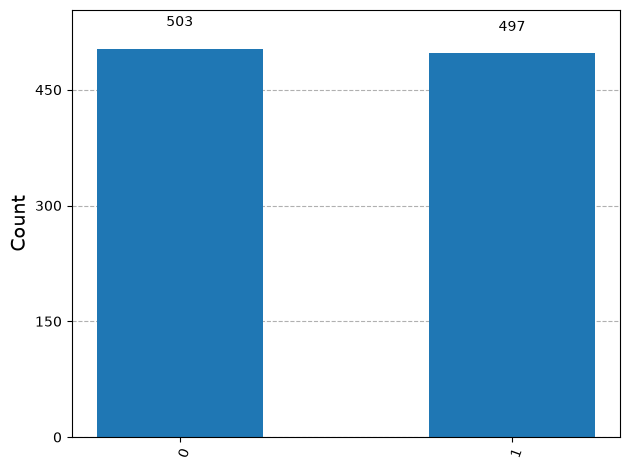

In [2]:
qc = QuantumCircuit(1, 1)  # 1 qubit, 1 classical bit
qc.h(0)                     # Apply Hadamard gate
qc.measure(0, 0)            # Measure

simulator = AerSimulator()
job = simulator.run(qc, shots=1000)
result = job.result()
counts = result.get_counts()

print("Circuit ran successfully!")
print(f"Results: {counts}")
plot_histogram(counts)

---

 ## Part 2: Complex Numbers



 **Background:** Quantum amplitudes are complex numbers.

 A complex number $z = a + bi$ where $i^2 = -1$.

 In Python/NumPy, use `1j` for the imaginary unit.

### Exercise 2.1

 Define the following complex numbers:

 - $z_1 = 3 + 4i$

 - $z_2 = 1 - 2i$

In [3]:
z1 = 3 + 4j  
z2 = 1 - 2j  

# Verify:
print(f"z1 = {z1}")
print(f"z2 = {z2}")

z1 = (3+4j)
z2 = (1-2j)


### Exercise 2.2

 Calculate the following (store results in variables):

 - a) $z_1 + z_2$

 - b) $z_1 \times z_2$

 - c) $z_1 / z_2$

In [4]:
sum_z = z1 + z2
product_z = z1 * z2
quotient_z = z1 / z2

print(f"z1 + z2 = {sum_z}")
print(f"z1 * z2 = {product_z}")
print(f"z1 / z2 = {quotient_z}")

z1 + z2 = (4+2j)
z1 * z2 = (11-2j)
z1 / z2 = (-1+2j)


### Exercise 2.3

 For $z_1 = 3 + 4i$, calculate:

 - a) Complex conjugate $z_1^*$ (use `.conjugate()` or `np.conj()`)

 - b) Magnitude $|z_1| = \sqrt{z_1 \cdot z_1^*}$

 - c) Verify: $|z_1|^2 = z_1 \cdot z_1^*$

In [5]:
z1_conj = np.conj(z1)     # complex conjugate
z1_magnitude = np.abs(z1) # magnitude |z1|

print(f"z1* = {z1_conj}")
print(f"|z1| = {z1_magnitude}")
print(f"|z1|² = {z1_magnitude**2 if z1_magnitude else None}")

z1* = (3-4j)
|z1| = 5.0
|z1|² = 25.0


### Exercise 2.4

 Euler's formula: $e^{i\theta} = \cos(\theta) + i \cdot \sin(\theta)$



 Calculate $e^{i\pi/4}$ two ways and verify they match:

In [6]:
theta = np.pi / 4

euler_formula = np.cos(theta) + 1j * np.sin(theta)  # use np.cos and np.sin
euler_direct = np.exp(1j * theta)   # use np.exp(1j * theta)

print(f"Using cos + i·sin: {euler_formula}")
print(f"Using np.exp:      {euler_direct}")
print(f"Match: {np.isclose(euler_formula, euler_direct) if euler_formula and euler_direct else 'incomplete'}")

Using cos + i·sin: (0.7071067811865476+0.7071067811865476j)
Using np.exp:      (0.7071067811865476+0.7071067811865476j)
Match: True


### Exercise 2.5

 The amplitude $\alpha = \frac{1+i}{\sqrt{2}}$ appears often in quantum computing.

 - a) Calculate $|\alpha|^2$ (this gives measurement probability)

 - b) Verify $|\alpha|^2 = 0.5$

In [7]:
alpha = (1 + 1j) / np.sqrt(2)

alpha_squared = np.abs(alpha)**2  

print(f"α = {alpha}")
print(f"|α|² = {alpha_squared}")

α = (0.7071067811865475+0.7071067811865475j)
|α|² = 1.0


---

 ## Part 3: Linear Algebra



 **Background:** Quantum states are vectors, gates are matrices.

### Exercise 3.1

 Define the computational basis states as column vectors:

 - $|0\rangle = [1, 0]^T$

 - $|1\rangle = [0, 1]^T$



 Use `dtype=complex` for all quantum state vectors.

In [8]:
ket_0 = np.array([1, 0], dtype=complex)  # np.array with shape (2,) or (2,1)
ket_1 = np.array([0, 1], dtype=complex)

print(f"|0⟩ = {ket_0}")
print(f"|1⟩ = {ket_1}")

|0⟩ = [1.+0.j 0.+0.j]
|1⟩ = [0.+0.j 1.+0.j]


### Exercise 3.2

 The Pauli matrices are fundamental quantum gates.

 Define the Pauli-X (NOT gate) and Pauli-Z matrices:



 $$X = \begin{pmatrix} 0 & 1 \\ 1 & 0 \end{pmatrix} \quad Z = \begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$$

In [9]:
X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

print(f"X =\n{X}")
print(f"Z =\n{Z}")

X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]
Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]


### Exercise 3.3

 Apply gates to states using matrix-vector multiplication (`@` or `np.dot`).

 Calculate:

 - a) $X|0\rangle$ (should give $|1\rangle$)

 - b) $X|1\rangle$ (should give $|0\rangle$)

 - c) $Z|0\rangle$ (should give $|0\rangle$)

 - d) $Z|1\rangle$ (should give $-|1\rangle$)

In [10]:
X_ket0 = X @ ket_0
X_ket1 = X @ ket_1
Z_ket0 = Z @ ket_0
Z_ket1 = Z @ ket_1

print(f"X|0⟩ = {X_ket0}")
print(f"X|1⟩ = {X_ket1}")
print(f"Z|0⟩ = {Z_ket0}")
print(f"Z|1⟩ = {Z_ket1}")

X|0⟩ = [0.+0.j 1.+0.j]
X|1⟩ = [1.+0.j 0.+0.j]
Z|0⟩ = [1.+0.j 0.+0.j]
Z|1⟩ = [ 0.+0.j -1.+0.j]


### Exercise 3.4

 The Hadamard gate creates superposition:



 $$H = \frac{1}{\sqrt{2}} \begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$$



 - a) Define H

 - b) Calculate $H|0\rangle$ (this is the $|+\rangle$ state)

 - c) Calculate $H|1\rangle$ (this is the $|-\rangle$ state)

In [11]:
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
H_ket0 = H @ ket_0 # this is |+⟩
H_ket1 = H @ ket_1 # this is |-⟩

print(f"H =\n{H}")
print(f"H|0⟩ = |+⟩ = {H_ket0}")
print(f"H|1⟩ = |-⟩ = {H_ket1}")

H =
[[ 0.70710678+0.j  0.70710678+0.j]
 [ 0.70710678+0.j -0.70710678+0.j]]
H|0⟩ = |+⟩ = [0.70710678+0.j 0.70710678+0.j]
H|1⟩ = |-⟩ = [ 0.70710678+0.j -0.70710678+0.j]


### Exercise 3.5

 Unitary matrices preserve vector length (normalization).

 A matrix $U$ is unitary if $U^\dagger U = I$, where $U^\dagger$ is the conjugate transpose.



 Verify that H is unitary:

 - a) Calculate $H^\dagger$ (use `.conj().T` or `np.conj(H).T`)

 - b) Calculate $H^\dagger H$

 - c) Check if result equals identity matrix $I$

In [12]:
H_dagger = np.conj(H).T       # conjugate transpose of H
H_dagger_H = H_dagger @ H     # H† @ H

print(f"H† =\n{H_dagger}")
print(f"H†H =\n{H_dagger_H}")
# Should be [[1,0],[0,1]] (identity matrix)

H† =
[[ 0.70710678-0.j  0.70710678-0.j]
 [ 0.70710678-0.j -0.70710678-0.j]]
H†H =
[[ 1.00000000e+00+0.j -2.23711432e-17+0.j]
 [-2.23711432e-17+0.j  1.00000000e+00+0.j]]


### Exercise 3.6

 Inner products give probability amplitudes.



 $\langle a|b \rangle = a^\dagger \cdot b$ (conjugate transpose of $a$, times $b$)



 Using $|+\rangle = H|0\rangle$ and $|-\rangle = H|1\rangle$ from Exercise 3.4:

 - a) Calculate $\langle 0|+\rangle$ (probability amplitude of measuring $|0\rangle$ in state $|+\rangle$)

 - b) Calculate $|\langle 0|+\rangle|^2$ (probability of measuring $|0\rangle$)

 - c) Calculate $\langle +|-\rangle$ (should be 0 — orthogonal states)

In [13]:
# Assuming you defined H_ket0 as |+⟩ above
ket_plus = H_ket0
ket_minus = H_ket1

inner_0_plus = np.vdot(ket_0, ket_plus)       # ⟨0|+⟩
prob_0_in_plus = np.abs(inner_0_plus)**2     # |⟨0|+⟩|²
inner_plus_minus = np.vdot(ket_plus, ket_minus)   # ⟨+|-⟩

print(f"⟨0|+⟩ = {inner_0_plus}")
print(f"|⟨0|+⟩|² = {prob_0_in_plus}")
print(f"⟨+|-⟩ = {inner_plus_minus}")  # Should be 0

⟨0|+⟩ = (0.7071067811865475+0j)
|⟨0|+⟩|² = 0.4999999999999999
⟨+|-⟩ = (-2.2371143170757382e-17+0j)
